# Onderdelen detecteren: alleen op het schaakbord (OpenCV)

**Opdracht:** automatische kandidaatdetectie zonder `labels/`, CNN, YOLO of handmatig gekozen objectlocaties. Alles buiten het schaakbord wordt genegeerd.

**Wat is nieuw?** De zwarte vakjes geven een eerste rasterschatting. Daarna controleren we of **een volledig raster van 8×11 vakjes** geometrisch én qua kleur overeenkomt met de foto. De bekende vakjesmiddens worden met een homografie rechtgetrokken. We segmenteren vervolgens uitsluitend in dat bordgebied.

**Status:** prototype, geen bewezen robuuste detector. De bounding boxes kunnen nog onvolledig zijn. Bij een onbetrouwbaar raster wordt de foto overgeslagen, niet alsnog een resultaat verzonnen. Classificatie volgt pas na betrouwbare detectie.

## 1. Afbeeldingen inladen

Plaats de afbeeldingen in `dataset/images/` of `images/`, of naast het notebook. Alleen JPG-bestanden worden geladen; `labels/` wordt nooit geopend.

In [18]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Zoek een map met foto's, zonder ooit labels te openen.
opties = [Path("dataset/images"), Path("images"), Path(".")]
MAP = next((p for p in opties if p.is_dir() and any(p.glob("*.jpg"))), None)
if MAP is None:
    raise FileNotFoundError("Geen JPG-foto's gevonden. Pas MAP aan.")

fotos = sorted(p for p in MAP.glob("*.jpg")
               if "leeg_schaakbord" not in p.stem.lower()
               and not p.stem.lower().startswith("prev_"))
print(f"Map: {MAP.resolve()}")
print(f"Aantal afbeeldingen: {len(fotos)}")

# Foto's worden verkleind om de verwerking redelijk snel te houden.
MAX_DIM = 860

def lees_foto(pad):
    img = cv2.imread(str(pad))
    if img is None:
        raise ValueError(f"Kan afbeelding niet laden: {pad}")
    h, w = img.shape[:2]
    factor = min(1.0, MAX_DIM / max(h, w))
    return cv2.resize(img, None, fx=factor, fy=factor)


Map: C:\Users\Gkain\OneDrive\Documenten\PythonCrashCourse\computer vision\dataset\images
Aantal afbeeldingen: 240


## 2. Zwarte vakjes herkennen en een eerste raster fitten

We gebruiken alleen de pixels en contouren. Dit is nog geen objectdetectie.

In [19]:
def vind_zwarte_vakken(img):
    grijs = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    glad = cv2.GaussianBlur(grijs, (3, 3), 0)
    _, donker = cv2.threshold(
        glad, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    contouren, _ = cv2.findContours(
        donker, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
    )
    kandidaten = []
    for contour in contouren:
        oppervlakte = cv2.contourArea(contour)
        if not 100 <= oppervlakte <= 6000:
            continue
        x, y, breedte, hoogte = cv2.boundingRect(contour)
        if min(breedte, hoogte) < 8:
            continue
        if max(breedte, hoogte) / min(breedte, hoogte) > 1.5:
            continue
        if oppervlakte / (breedte * hoogte) < 0.58:
            continue
        poly = cv2.approxPolyDP(
            contour, 0.065 * cv2.arcLength(contour, True), True
        )
        if not 4 <= len(poly) <= 6:
            continue
        # Een witte binnencontour telt niet als zwart vakje.
        cx = int(np.clip(x + breedte // 2, 0, grijs.shape[1] - 1))
        cy = int(np.clip(y + hoogte // 2, 0, grijs.shape[0] - 1))
        if donker[cy, cx] == 0:
            continue
        rechthoek = cv2.minAreaRect(contour)
        kandidaten.append((np.array(rechthoek[0]), oppervlakte, rechthoek))

    if len(kandidaten) < 6:
        raise ValueError("Te weinig zwarte vierkanten gevonden")
    oppervlaktes = np.array([c[1] for c in kandidaten])
    normaal = np.median(oppervlaktes)
    kandidaten = [c for c in kandidaten
                  if 0.55 * normaal < c[1] < 1.75 * normaal]
    if len(kandidaten) < 6:
        raise ValueError("Te weinig vierkanten met vergelijkbare grootte")
    return kandidaten


def pas_raster(kandidaten):
    posities = np.array([c[0] for c in kandidaten])
    vakgrootte = float(np.sqrt(np.median([c[1] for c in kandidaten])))

    # Een vierkant is bij 0 en 90 graden dezelfde vorm.
    hoeken = np.array([(c[2][2] + 45) % 90 - 45 for c in kandidaten])
    theta = np.deg2rad(float(np.median(hoeken)))
    u = vakgrootte * np.array([np.cos(theta), np.sin(theta)])
    v = vakgrootte * np.array([-np.sin(theta), np.cos(theta)])
    basis = np.column_stack([u, v])
    inverse = np.linalg.inv(basis)

    beste = None
    for anker in posities:
        indices = np.rint((posities - anker) @ inverse.T).astype(int)
        voorspeld = anker + indices @ basis.T
        fouten = np.linalg.norm(posities - voorspeld, axis=1)
        # Zwarte vakjes liggen op dezelfde pariteit van het schaakbord.
        inliers = ((fouten < 0.26 * vakgrootte)
                   & ((indices[:, 0] + indices[:, 1]) % 2 == 0))
        score = np.sum(inliers * (1 - np.minimum(fouten / vakgrootte, 1)))
        if beste is None or score > beste[0]:
            beste = (score, anker, indices, inliers)

    _, anker, indices, inliers = beste
    if inliers.sum() < 6:
        raise ValueError("Raster onbetrouwbaar: onvoldoende overeenkomende vakjes")

    # Kleine aanpassing van de rasterafstand en verschuiving.
    trans = np.array([anker, u, v], dtype=float)
    for _ in range(4):
        A = np.column_stack([np.ones(inliers.sum()), indices[inliers]])
        kandidaat_trans = np.linalg.lstsq(A, posities[inliers], rcond=None)[0]
        nu, nv = kandidaat_trans[1], kandidaat_trans[2]
        if not (0.80 * vakgrootte < np.linalg.norm(nu) < 1.20 * vakgrootte
                and 0.80 * vakgrootte < np.linalg.norm(nv) < 1.20 * vakgrootte):
            break
        basis_nieuw = np.column_stack([kandidaat_trans[1], kandidaat_trans[2]])
        indices_nieuw = np.rint(
            (posities - kandidaat_trans[0]) @ np.linalg.inv(basis_nieuw).T
        ).astype(int)
        fouten = np.linalg.norm(
            posities - (kandidaat_trans[0] + indices_nieuw @ basis_nieuw.T),
            axis=1
        )
        inliers_nieuw = ((fouten < 0.22 * vakgrootte)
                        & ((indices_nieuw[:, 0] + indices_nieuw[:, 1]) % 2 == 0))
        if inliers_nieuw.sum() < 6:
            break  # Houd vorige, betrouwbaardere schatting.
        trans, indices, inliers = kandidaat_trans, indices_nieuw, inliers_nieuw

    # Affiene projectie van rastercoördinaten naar de foto.
    M = np.array([[trans[1, 0], trans[2, 0], trans[0, 0]],
                  [trans[1, 1], trans[2, 1], trans[0, 1]],
                  [0., 0., 1.]], dtype=np.float64)

    return M, indices[inliers], inliers, vakgrootte


## 3. Volledig schaakbord lokaliseren en controleren

We zoeken een rechthoekig raster van **8×11 of 11×8 vakjes**. Kandidaten die op zwart plakband of losse voorwerpen lijken, mogen geen aanleiding zijn om het bord buiten zijn echte grenzen te plaatsen. De code controleert daarom de verwachte zwart-witverdeling en geeft een foutmelding als de rastercontrole onvoldoende is.

In [20]:
def selecteer_bord(img, kandidaten, M, vakgrootte):
    k = kandidaten
    v = vakgrootte
    h,w=img.shape[:2]
    centers=np.array([a[0] for a in k],dtype=np.float32)
    uv=cv2.perspectiveTransform(centers.reshape(-1,1,2),np.linalg.inv(M)).reshape(-1,2)
    ind=np.rint(uv).astype(int)
    reconstructed=cv2.perspectiveTransform(ind.reshape(-1,1,2).astype(np.float32),M).reshape(-1,2)
    err=np.linalg.norm(reconstructed-centers,axis=1)
    valid=(err < .28*v) & ((ind.sum(axis=1)%2)==0)
    inlier_idx=ind[valid]
    if len(inlier_idx)<8:raise ValueError('Minder dan 8 betrouwbare zwarte vakjes')
    gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    variants=[]
    span=np.ptp(inlier_idx,axis=0)
    for cols,rows in [(8,11),(11,8)]:
       # all possible [x0..x0+cols-1] include a substantial portion of known candidates
       for x0 in range(int(inlier_idx[:,0].min()-cols+2),int(inlier_idx[:,0].max())):
        for y0 in range(int(inlier_idx[:,1].min()-rows+2),int(inlier_idx[:,1].max())):
         xi=np.arange(x0,x0+cols)
         yi=np.arange(y0,y0+rows)
         uu,vv=np.meshgrid(xi,yi)
         tilegrid=np.stack([uu.ravel(),vv.ravel()],axis=-1).astype('float32')
         pix=cv2.perspectiveTransform(tilegrid.reshape(-1,1,2),M).reshape(-1,2)
         xs=np.rint(pix[:,0]).astype(int);ys=np.rint(pix[:,1]).astype(int)
         inside=(xs>8)&(ys>8)&(xs<w-8)&(ys<h-8)
         if inside.mean()<.95:continue
         # check color polarization with global Otsu? detect dark squares vs white paper on board. use fixed medians from candidate black squares and nearby one-away whites
         patchvals=np.zeros(len(xs),float)
         for j0,(x,y) in enumerate(zip(xs,ys)):
          if inside[j0]:
           patchvals[j0]=np.median(gray[y-4:y+5,x-4:x+5])
         dark_expected=((tilegrid[:,0]+tilegrid[:,1])%2)==0
         black=patchvals[dark_expected&inside];white=patchvals[(~dark_expected)&inside]
         if len(black)<20 or len(white)<20:continue
         bc=np.median(black);wc=np.median(white)
         contrast=wc-bc
         if contrast<65:continue
         t=(bc+wc)/2
         correct=((dark_expected & (patchvals<t)) | ((~dark_expected)&(patchvals>=t))) & inside
         # robust standardized signed contrast + regularity
         score=np.mean(correct)*contrast + (correct.mean()-.5)*40
         # from inliers fraction in region
         within=((inlier_idx[:,0]>=x0)&(inlier_idx[:,0]<x0+cols)&(inlier_idx[:,1]>=y0)&(inlier_idx[:,1]<y0+rows))
         cnt=within.sum()
         score+=min(cnt,40)*.2
         variants.append((score,cols,rows,x0,y0,correct.mean(),contrast,cnt))
    if not variants:raise ValueError('Geen volledige bordregio met duidelijk zwart-wit patroon')
    result=max(variants)
    _,cols,rows,x0,y0,acc,contrast,cnt=result
    if acc<.79:raise ValueError(f'Schaakbordpatroon niet betrouwbaar ({acc:.0%} overeenstemming)')
    # refine H using known black squares WITHIN chosen region
    within=valid&(ind[:,0]>=x0)&(ind[:,0]<x0+cols)&(ind[:,1]>=y0)&(ind[:,1]<y0+rows)
    if within.sum()<8:raise ValueError('Te weinig punten binnen schaakbord')
    H,mask=cv2.findHomography(ind[within].astype(np.float32),centers[within],cv2.RANSAC,3.0)
    if H is None:raise ValueError('Homografie mislukt')
    meanerr=np.median(np.linalg.norm(cv2.perspectiveTransform(ind[within].reshape(-1,1,2).astype('float32'),H).reshape(-1,2)-centers[within],axis=1))
    return H,(cols,rows,x0,y0,acc,contrast,cnt,meanerr),inlier_idx

## 4. Alleen binnen het bord objectkandidaten detecteren

De foto wordt perspectivisch rechtgetrokken naar 52 pixels per vakje. Van elk vakje schatten we een donkere of lichte achtergrondkleur, gebaseerd op pixels van het gevonden bord. `cv2.connectedComponentsWithStats` vindt afwijkende gebieden; hun rechthoeken worden ook op de originele foto teruggeprojecteerd. **De kleur- en vormclassificatie is nog niet af.**

In [21]:
def detecteer_op_bord(img):
 k=vind_zwarte_vakken(img);M,idx,inl,v=pas_raster(k)
 H,detail,ind=selecteer_bord(img,k,M,v)
 cols,rows,x0,y0,acc,contrast,cnt,meanerr=detail
 cell=52
 t=np.array([[1/cell,0,x0-.5],[0,1/cell,y0-.5],[0,0,1]],dtype='float64')
 output2orig=H@t
 bord=cv2.warpPerspective(img,np.linalg.inv(output2orig),(cols*cell,rows*cell))
 # background color estimation
 h,w=bord.shape[:2]
 gray=cv2.cvtColor(bord,cv2.COLOR_BGR2GRAY)
 lab=cv2.cvtColor(bord,cv2.COLOR_BGR2LAB).astype('float32')
 YY,XX=np.indices((h,w));iu=XX//cell;iv=YY//cell;parity=((iu+iv+x0+y0)%2==0)
 safe=(np.minimum(XX%cell,cell-1-XX%cell)>9)&(np.minimum(YY%cell,cell-1-YY%cell)>9)
 # dark/light per tile matching offset
 cblack=np.median(lab[safe&parity],axis=0);cwhite=np.median(lab[safe&~parity],axis=0)
 model=np.where(parity[:,:,None],cblack,cwhite)
 # illumination correction via medblur / Gaussian sigma 38
 bg_err=cv2.GaussianBlur(lab[:,:,0]-model[:,:,0],(0,0),cell*1.4)
 model[:,:,0]+=np.clip(bg_err,-15,15)
 delta=np.abs(lab-model)
 score=.5*delta[:,:,0]+.25*delta[:,:,1]+.25*delta[:,:,2]
 vals=score[safe]; med=np.median(vals); mad=np.median(np.abs(vals-med));thr=max(30,med+5*1.4826*mad)
 
# Kleinere marge rond de schaakbordlijnen
 marge = 3
 
 binnen = (
     (np.minimum(XX % cell, cell - 1 - XX % cell) > marge)
     &
     (np.minimum(YY % cell, cell - 1 - YY % cell) > marge)
 )

 mask = np.uint8((score > thr) & binnen) * 255

 mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3)))
 mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(17,17)))
 count,labels,stats,_=cv2.connectedComponentsWithStats(mask,8)
 detections=[]
 display=bord.copy()
 volledig=img.copy()
 for i in range(1,count):
  x,y,bw,bh,area=stats[i];
  if area<80 or min(bw,bh)<8 or area>.1*w*h:continue
  detections.append((int(x),int(y),int(bw),int(bh),int(area)))
  cv2.rectangle(display,(x,y),(x+bw,y+bh),(0,255,0),2)
  # Vier hoekpunten van de detectie terugprojecteren naar de originele foto.
  hoekjes=np.float32([[x,y],[x+bw,y],[x+bw,y+bh],[x,y+bh]]).reshape(-1,1,2)
  origineel_hoekjes=cv2.perspectiveTransform(hoekjes,output2orig)
  cv2.polylines(volledig,[np.rint(origineel_hoekjes).astype(np.int32)],True,(0,255,0),2)
 # De bordrand ook terugprojecteren; detectie gebeurt alleen BINNEN dit gebied.
 bordhoeken=np.float32([[0,0],[w-1,0],[w-1,h-1],[0,h-1]]).reshape(-1,1,2)
 bord_hoekjes=cv2.perspectiveTransform(bordhoeken,output2orig)
 cv2.polylines(volledig,[np.rint(bord_hoekjes).astype(np.int32)],True,(255,0,255),2)
 return {'board':bord,'model':cv2.cvtColor(np.uint8(np.clip(model,0,255)),cv2.COLOR_LAB2BGR),
         'mask':mask,'res':display,'origineel':volledig,'details':detail,
         'detections':detections,'H':H,'overeenkomst':acc,'reprojectiefout':meanerr}

## 5. Test op meerdere foto’s

Dezelfde instellingen worden gebruikt voor alle afbeeldingen. We tonen zowel de originele foto met de paarse **bordgrens** en groene **kandidaatboxen** als het rechtgetrokken bord, achtergrondmodel en masker.

20261106_133457_v_flip.jpg: overgeslagen — Raster onbetrouwbaar: onvoldoende overeenkomende vakjes
20261106_132431_h_flip.jpg: 18 kandidaatobjecten
20261106_132843_h_flip.jpg: overgeslagen — Te weinig zwarte vierkanten gevonden
20261106_132042_hv_flip.jpg: 1 kandidaatobjecten
20261106_132205_hv_flip.jpg: 21 kandidaatobjecten
20261106_133323_h_flip.jpg: overgeslagen — Te weinig zwarte vierkanten gevonden
20261106_132245_h_flip.jpg: overgeslagen — Te weinig vierkanten met vergelijkbare grootte
20261106_133614.jpg: overgeslagen — Te weinig zwarte vierkanten gevonden
20261106_132854_v_flip.jpg: overgeslagen — Te weinig zwarte vierkanten gevonden
20261106_133026_v_flip.jpg: overgeslagen — Te weinig zwarte vierkanten gevonden
20261106_132912.jpg: overgeslagen — Te weinig zwarte vierkanten gevonden
20261106_132206.jpg: overgeslagen — Raster onbetrouwbaar: onvoldoende overeenkomende vakjes
20261106_133647_hv_flip.jpg: overgeslagen — Raster onbetrouwbaar: onvoldoende overeenkomende vakjes
20261

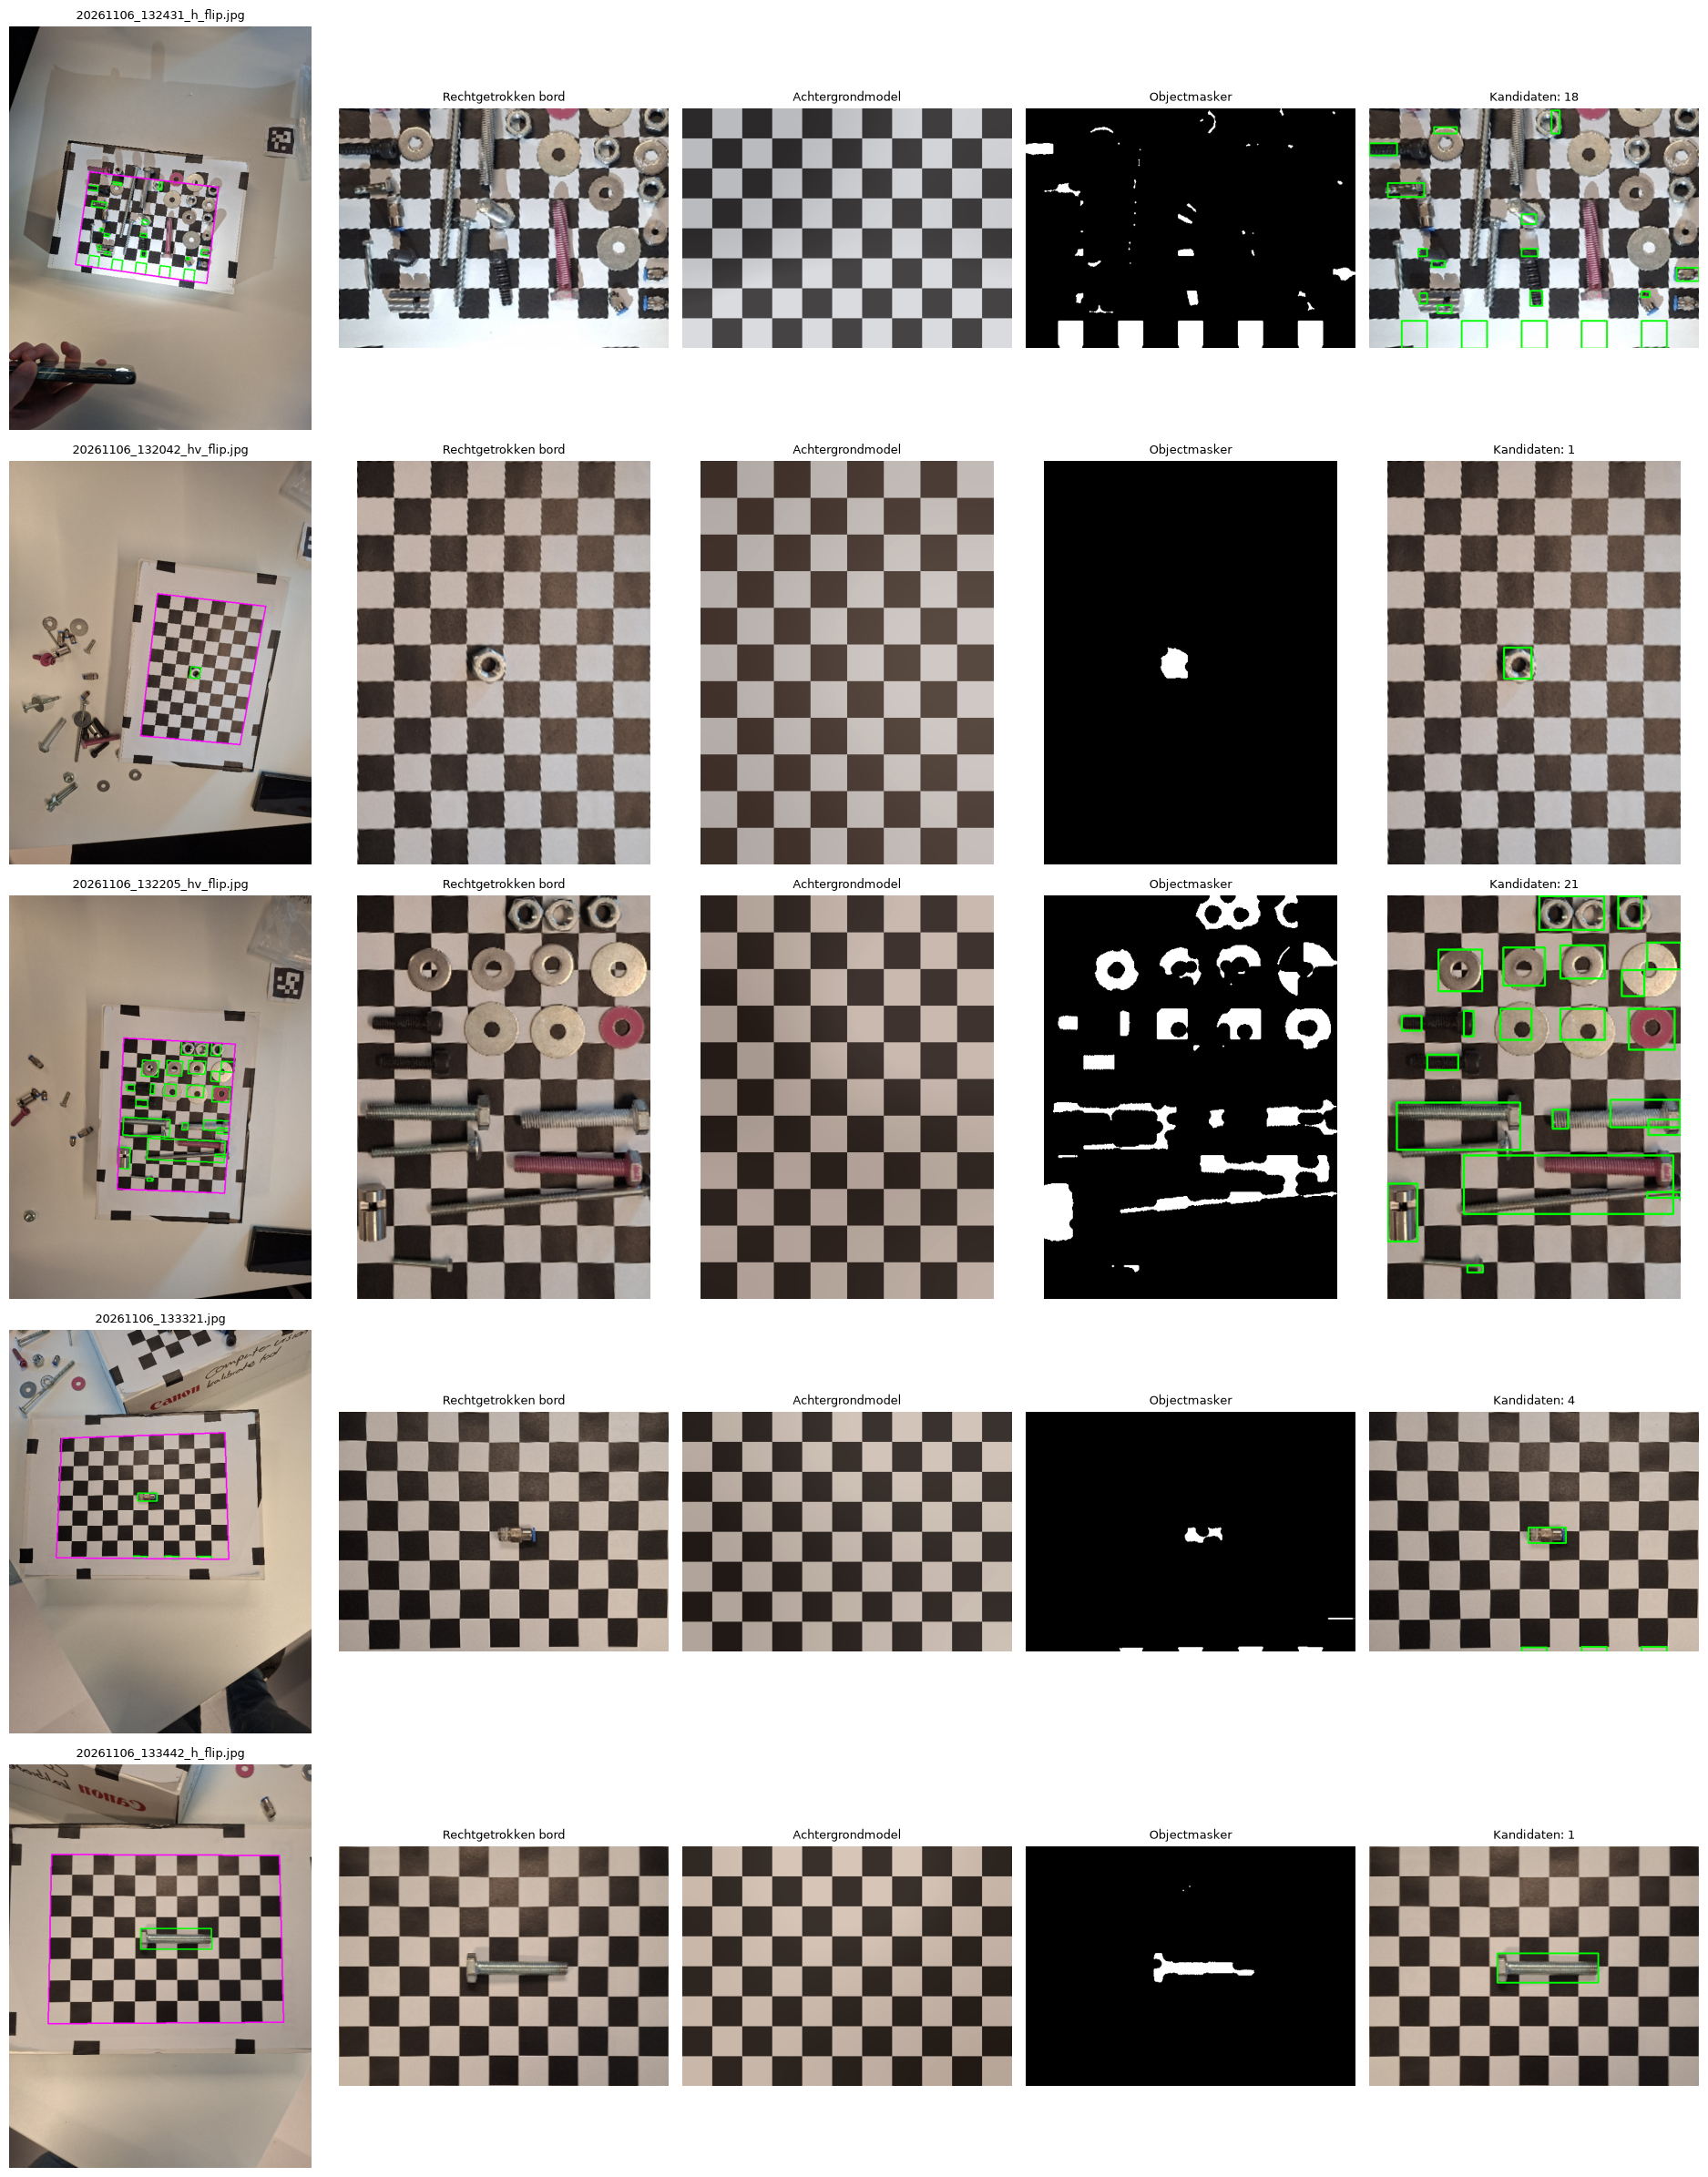

In [24]:

# BLOK 5 — Willekeurige afbeeldingen testen

import random
from collections import Counter

AANTAL_TESTS = 5
MAX_POGINGEN = min(30, len(fotos))

# Willekeurige volgorde zonder herhaling
selectie = random.sample(fotos, MAX_POGINGEN)

resultaten = []
fouten = Counter()
geprobeerd = 0

for pad in selectie:

    if len(resultaten) >= AANTAL_TESTS:
        break

    geprobeerd += 1

    try:
        d = detecteer_op_bord(lees_foto(pad))

        resultaten.append((pad.name, d))

        print(
            f"{pad.name}: "
            f"{len(d['detections'])} kandidaatobjecten"
        )

    except (ValueError, RuntimeError, cv2.error) as fout:
        fouten[str(fout)] += 1
        print(f"{pad.name}: overgeslagen — {fout}")

print("\n--- SAMENVATTING ---")
print("Geprobeerd:", geprobeerd)
print("Succesvol verwerkt:", len(resultaten))
print("Overgeslagen:", geprobeerd - len(resultaten))
print("Redenen:", dict(fouten))

# Resultaten tonen
if resultaten:

    fig, assen = plt.subplots(
        len(resultaten), 5,
        figsize=(19, 4.8 * len(resultaten)),
        squeeze=False
    )

    for rij, (naam, d) in enumerate(resultaten):

        beelden = [
            d["origineel"],
            d["board"],
            d["model"],
            d["mask"],
            d["res"]
        ]

        titels = [
            naam,
            "Rechtgetrokken bord",
            "Achtergrondmodel",
            "Objectmasker",
            f"Kandidaten: {len(d['detections'])}"
        ]

        for j, (beeld, titel) in enumerate(zip(beelden, titels)):

            if j == 3:
                assen[rij, j].imshow(beeld, cmap="gray")
            else:
                assen[rij, j].imshow(
                    cv2.cvtColor(beeld, cv2.COLOR_BGR2RGB)
                )

            assen[rij, j].set_title(titel, fontsize=9)
            assen[rij, j].axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("Geen afbeelding kon betrouwbaar verwerkt worden.")


## Wat is er getest?

- Op vier beschikbare testfoto’s kon de oorspronkelijke zwarte-vakjesdetectie bij **twee** foto’s een eerste raster vinden. De drukke foto's blijven lastig.
- Voor de twee geslaagde rasterfits sluit de nieuwe bordregio aan op het zichtbare schaakbord. De nieuwe geometrie beperkt de afwijkingen buiten het bord en de meeste foutieve detecties op de geteste enkelvoudige objectfoto’s.
- **De echte onderdelen zijn nog niet altijd volledig gesegmenteerd:** bijvoorbeeld alleen de kop of een deel van de schacht van een bout. Dat is een bekende beperking, geen succesvolle volledige detectie.
- Positie en oriëntatie moeten pas definitief gerapporteerd worden zodra de objectcontour volledig genoeg is. Een cirkelvormig onderdeel heeft sowieso geen unieke in-vlak-orientatie.

**Volgende test:** vergelijk op 5–10 verschillende foto's het aantal echte objecten dat **volledig** binnen een kandidaatbox ligt, het aantal gemiste objecten en het aantal foutieve boxes. Alle onderdelen buiten de paarse bordgrens mogen buiten beschouwing blijven.

In [23]:

# BLOK 6 — Buitencontour van ronde onderdelen verfijnen
# Vereist: resultaten uit de vorige cel
# Geen labels, CNN of YOLO

import cv2
import numpy as np
import matplotlib.pyplot as plt

VAK = 52

def verfijn_rond_object(bord, detectie):

    x, y, bw, bh, _ = detectie

    cx = x + bw / 2
    cy = y + bh / 2

    h, w = bord.shape[:2]

    # 1. Zoekgebied rondom de kandidaat
    marge = int(1.2 * VAK)

    x0 = max(0, int(cx - marge))
    y0 = max(0, int(cy - marge))
    x1 = min(w, int(cx + marge))
    y1 = min(h, int(cy + marge))

    roi = bord[y0:y1, x0:x1]

    if min(roi.shape[:2]) < 30:
        return None

    # 2. Ronde vormen zoeken
    grijs = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    glad = cv2.GaussianBlur(grijs, (5, 5), 1.2)

    cirkels = cv2.HoughCircles(
        glad,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=VAK // 2,
        param1=110,
        param2=18,
        minRadius=VAK // 6,
        maxRadius=int(0.6 * VAK)
    )

    if cirkels is None:
        return None

    # Kies de cirkel dicht bij de kandidaat
    opties = []

    for px, py, r in cirkels[0]:

        px += x0
        py += y0

        afstand = np.hypot(px - cx, py - cy)

        if afstand < 0.4 * VAK:
            opties.append((afstand, px, py, r))

    if not opties:
        return None

    _, px, py, r = min(opties)

    # 3. GrabCut rondom de gevonden cirkel
    marge = int(max(26, 2 * r))

    xa = max(0, int(px - marge))
    ya = max(0, int(py - marge))
    xb = min(w, int(px + marge))
    yb = min(h, int(py + marge))

    uitsnede = bord[ya:yb, xa:xb].copy()

    hh, ww = uitsnede.shape[:2]

    Y, X = np.indices((hh, ww))

    afstand = np.sqrt(
        (X - (px - xa))**2 +
        (Y - (py - ya))**2
    )

    # Achtergrond en voorgrond automatisch schatten
    gc_mask = np.full(
        (hh, ww), cv2.GC_PR_BGD, np.uint8
    )

    gc_mask[afstand < 1.25*r] = cv2.GC_PR_FGD

    # Ringvormig gebied als zekere voorgrond
    gc_mask[
        (afstand > 0.55*r) &
        (afstand < 0.90*r)
    ] = cv2.GC_FGD

    # Gat van de ring en omgeving als achtergrond
    gc_mask[afstand < 0.38*r] = cv2.GC_BGD
    gc_mask[afstand > 1.65*r] = cv2.GC_BGD

    bg = np.zeros((1, 65), np.float64)
    fg = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        uitsnede,
        gc_mask,
        None,
        bg,
        fg,
        5,
        cv2.GC_INIT_WITH_MASK
    )

    objectmasker = np.uint8(
        (gc_mask == cv2.GC_FGD) |
        (gc_mask == cv2.GC_PR_FGD)
    ) * 255

    # 4. Buitencontour zoeken
    contouren, _ = cv2.findContours(
        objectmasker,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contouren:
        return None

    contour = max(contouren, key=cv2.contourArea)

    if cv2.contourArea(contour) < 0.25 * np.pi * r*r:
        return None

    # Coördinaten terug naar het volledige bord
    contour = contour + np.array([[[xa, ya]]])

    return contour


# 5. Resultaten vergelijken
fig, assen = plt.subplots(
    len(resultaten), 2,
    figsize=(11, 4.5 * len(resultaten)),
    squeeze=False
)

for i, (naam, d) in enumerate(resultaten):

    origineel = d["res"]
    verbeterd = d["board"].copy()

    gevonden = 0

    for detectie in d["detections"]:

        try:
            contour = verfijn_rond_object(
                d["board"], detectie
            )
        except cv2.error:
            contour = None

        if contour is None:
            continue

        gevonden += 1

        # Volledige contour tekenen
        cv2.drawContours(
            verbeterd, [contour], -1,
            (0, 0, 255), 2
        )

        # Bounding box rondom volledige contour
        x, y, bw, bh = cv2.boundingRect(contour)

        cv2.rectangle(
            verbeterd,
            (x, y),
            (x+bw, y+bh),
            (0, 255, 0), 2
        )

    print(f"{naam}: {gevonden} ronde objecten verfijnd")

    assen[i, 0].imshow(
        cv2.cvtColor(origineel, cv2.COLOR_BGR2RGB)
    )
    assen[i, 0].set_title("Oorspronkelijke detectie")

    assen[i, 1].imshow(
        cv2.cvtColor(verbeterd, cv2.COLOR_BGR2RGB)
    )
    assen[i, 1].set_title(
        f"Verfijnde buitencontour: {gevonden}"
    )

    for ax in assen[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


ValueError: Number of rows must be a positive integer, not 0

<Figure size 1100x0 with 0 Axes>


Afbeelding: 20261106_132205_v_flip.jpg
Onderdeel 1:
  Middelpunt: (64.0, 24.0)
  Breedte: 28.0 pixels
  Hoogte: 26.0 pixels
  Oriëntatie: Niet eenduidig (bijna rond/vierkant)
Onderdeel 2:
  Middelpunt: (128.5, 26.5)
  Breedte: 53.0 pixels
  Hoogte: 55.0 pixels
  Oriëntatie: Niet eenduidig (bijna rond/vierkant)
Onderdeel 3:
  Middelpunt: (177.6, 26.0)
  Breedte: 47.1 pixels
  Hoogte: 45.0 pixels
  Oriëntatie: Niet eenduidig (bijna rond/vierkant)
Onderdeel 5:
  Middelpunt: (139.8, 96.8)
  Breedte: 60.1 pixels
  Hoogte: 60.8 pixels
  Oriëntatie: Niet eenduidig (bijna rond/vierkant)
Onderdeel 12:
  Middelpunt: (36.5, 186.0)
  Breedte: 62.0 pixels
  Hoogte: 73.0 pixels
  Oriëntatie: Niet eenduidig (bijna rond/vierkant)
Onderdeel 14:
  Middelpunt: (131.5, 193.0)
  Breedte: 22.0 pixels
  Hoogte: 23.0 pixels
  Oriëntatie: Niet eenduidig (bijna rond/vierkant)
Onderdeel 15:
  Middelpunt: (225.5, 189.0)
  Breedte: 22.0 pixels
  Hoogte: 23.0 pixels
  Oriëntatie: Niet eenduidig (bijna rond/vierkan

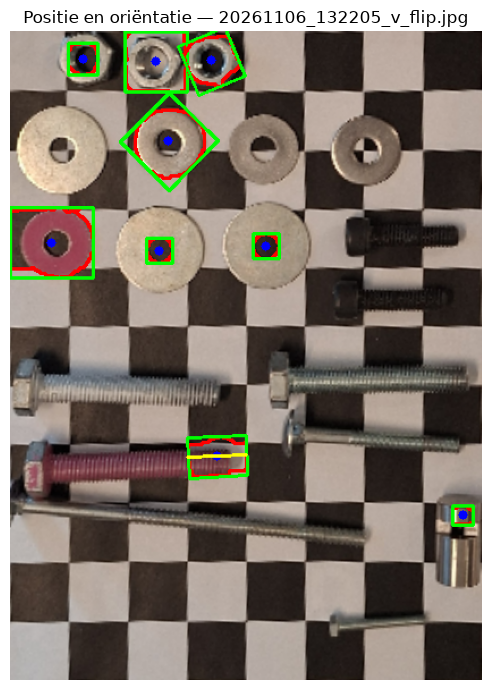

In [ ]:

# BLOK 7 — Positie en oriëntatie bepalen
# Vereist: resultaten en verfijn_rond_object() uit blok 6

import cv2
import numpy as np
import matplotlib.pyplot as plt

fig, assen = plt.subplots(
    len(resultaten), 1,
    figsize=(7, 7 * len(resultaten)),
    squeeze=False
)

for i, (naam, d) in enumerate(resultaten):

    beeld = d["board"].copy()

    print(f"\nAfbeelding: {naam}")

    for nummer, detectie in enumerate(d["detections"], start=1):

        # 1. Verbeterde contour ophalen
        contour = verfijn_rond_object(
            d["board"], detectie
        )

        if contour is None:
            continue

        # 2. Kleinste gedraaide rechthoek
        rect = cv2.minAreaRect(contour)

        (cx, cy), (breedte, hoogte), hoek = rect

        # 3. Hoek van de lange zijde bepalen
        if breedte < hoogte:
            hoek += 90

        hoek = hoek % 180

        # 4. Hoekpunten van gedraaide rechthoek
        punten = cv2.boxPoints(rect)
        punten = np.int32(np.round(punten))

        # 5. Buitencontour tekenen (rood)
        cv2.drawContours(
            beeld, [contour], -1,
            (0, 0, 255), 2
        )

        # 6. Gedraaide bounding box (groen)
        cv2.drawContours(
            beeld, [punten], 0,
            (0, 255, 0), 2
        )

        # 7. Middelpunt tekenen (blauw)
        cv2.circle(
            beeld,
            (int(cx), int(cy)),
            4,
            (255, 0, 0),
            -1
        )

        # 8. Oriëntatielijn voor langwerpige objecten
        lange_zijde = max(breedte, hoogte)
        korte_zijde = max(1, min(breedte, hoogte))

        verhouding = lange_zijde / korte_zijde

        if verhouding > 1.2:

            lengte = lange_zijde / 2

            dx = lengte * np.cos(np.radians(hoek))
            dy = lengte * np.sin(np.radians(hoek))

            begin = (
                int(cx - dx),
                int(cy - dy)
            )

            eind = (
                int(cx + dx),
                int(cy + dy)
            )

            cv2.line(
                beeld, begin, eind,
                (0, 255, 255), 2
            )

            oriëntatie = f"{hoek:.1f} graden"

        else:
            oriëntatie = "Niet eenduidig (bijna rond/vierkant)"

        print(f"Onderdeel {nummer}:")
        print(f"  Middelpunt: ({cx:.1f}, {cy:.1f})")
        print(f"  Breedte: {breedte:.1f} pixels")
        print(f"  Hoogte: {hoogte:.1f} pixels")
        print(f"  Oriëntatie: {oriëntatie}")

    assen[i, 0].imshow(
        cv2.cvtColor(beeld, cv2.COLOR_BGR2RGB)
    )

    assen[i, 0].set_title(
        f"Positie en oriëntatie — {naam}"
    )

    assen[i, 0].axis("off")

plt.tight_layout()
plt.show()



Afbeelding: 20261106_132205_v_flip.jpg
  Object 1: positie=(64.0, 24.0), verhouding=1.08, hoek=90.0°
  Object 2: positie=(128.5, 26.5), verhouding=1.04, hoek=0.0°
  Object 3: positie=(177.6, 26.0), verhouding=1.05, hoek=67.2°
  Object 4: positie=(141.0, 99.0), verhouding=1.00, hoek=90.0°
  Object 5: positie=(223.0, 103.5), verhouding=1.02, hoek=45.0°
  Object 6: positie=(36.5, 186.0), verhouding=1.18, hoek=0.0°
  Object 7: positie=(42.5, 186.0), verhouding=1.02, hoek=90.0°
  Object 8: positie=(131.5, 193.0), verhouding=1.05, hoek=0.0°
  Object 9: positie=(225.5, 189.0), verhouding=1.05, hoek=0.0°
  Object 10: positie=(336.5, 236.5), verhouding=2.37, hoek=0.0°
  Object 11: positie=(384.0, 300.5), verhouding=1.79, hoek=0.0°
  Object 12: positie=(284.0, 303.0), verhouding=2.00, hoek=0.0°
  Object 13: positie=(27.0, 320.0), verhouding=1.28, hoek=0.0°
  Object 14: positie=(249.9, 340.2), verhouding=1.36, hoek=71.6°
  Object 15: positie=(175.9, 377.7), verhouding=1.27, hoek=177.1°
  Object 

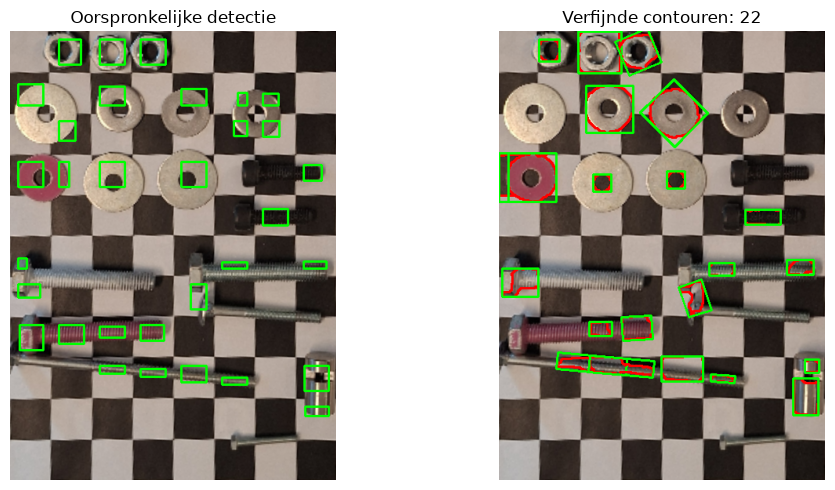

In [ ]:

# BLOK 8 — Algemene contourverfijning
# Vereist: resultaten en verfijn_rond_object()
# Geen labels, CNN of YOLO

import cv2
import numpy as np
import matplotlib.pyplot as plt


def verfijn_langwerpig(bord, model, masker, detectie):

    x, y, bw, bh = map(int, detectie[:4])
    h, w = bord.shape[:2]

    # 1. Ruimer zoekgebied rondom de kandidaat
    marge = min(140, max(45, int(1.7 * max(bw, bh))))

    x0 = max(0, x - marge)
    y0 = max(0, y - marge)
    x1 = min(w, x + bw + marge)
    y1 = min(h, y + bh + marge)

    roi = bord[y0:y1, x0:x1].copy()
    rh, rw = roi.shape[:2]

    if min(rh, rw) < 20:
        return None

    # 2. Bestaand objectmasker als startpunt
    zaad = np.zeros((rh, rw), dtype=np.uint8)

    zaad[
        y-y0:y+bh-y0,
        x-x0:x+bw-x0
    ] = masker[y:y+bh, x:x+bw]

    if cv2.countNonZero(zaad) < 10:
        return None

    # 3. Vergelijk met het schaakbordachtergrondmodel
    lab_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2LAB)
    lab_model = cv2.cvtColor(
        model[y0:y1, x0:x1],
        cv2.COLOR_BGR2LAB
    )

    delta = cv2.absdiff(
        lab_roi, lab_model
    ).astype(np.float32)

    score = (
        0.55 * delta[:, :, 0]
        + 0.225 * delta[:, :, 1]
        + 0.225 * delta[:, :, 2]
    )

    # 4. GrabCut automatisch initialiseren
    gc_mask = np.full(
        (rh, rw),
        cv2.GC_PR_BGD,
        dtype=np.uint8
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (29, 29)
    )

    omgeving = cv2.dilate(
        zaad, kernel, iterations=2
    )

    gc_mask[
        (omgeving > 0) & (score > 23)
    ] = cv2.GC_PR_FGD

    # Buitenste pixels zeker achtergrond
    gc_mask[:4, :] = cv2.GC_BGD
    gc_mask[-4:, :] = cv2.GC_BGD
    gc_mask[:, :4] = cv2.GC_BGD
    gc_mask[:, -4:] = cv2.GC_BGD

    # Kern van de oorspronkelijke detectie
    zeker = cv2.erode(
        zaad,
        cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
    )

    gc_mask[zeker > 0] = cv2.GC_FGD

    if not np.any(gc_mask == cv2.GC_FGD):
        return None

    bg = np.zeros((1, 65), np.float64)
    fg = np.zeros((1, 65), np.float64)

    try:
        cv2.grabCut(
            roi, gc_mask, None,
            bg, fg, 3,
            cv2.GC_INIT_WITH_MASK
        )
    except cv2.error:
        return None

    # 5. Contouren vinden
    objectmasker = np.uint8(
        (gc_mask == cv2.GC_FGD) |
        (gc_mask == cv2.GC_PR_FGD)
    ) * 255

    objectmasker = cv2.morphologyEx(
        objectmasker,
        cv2.MORPH_OPEN,
        cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
    )

    contouren, _ = cv2.findContours(
        objectmasker,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Kies een contour die de originele detectie bevat
    kandidaten = []

    for contour in contouren:

        oppervlakte = cv2.contourArea(contour)

        if oppervlakte < 40 or oppervlakte > 0.5 * rh * rw:
            continue

        test = np.zeros_like(zaad)

        cv2.drawContours(
            test, [contour], -1, 255, -1
        )

        overlap = cv2.countNonZero(
            cv2.bitwise_and(test, zaad)
        )

        if overlap < 0.2 * cv2.countNonZero(zaad):
            continue

        kandidaten.append((overlap, contour))

    if not kandidaten:
        return None

    contour = max(
        kandidaten, key=lambda item: item[0]
    )[1]

    # Terug naar coördinaten van het volledige bord
    return contour + np.array([[[x0, y0]]])


# ==========================================
# 6. RONDE EN LANGWERPIGE OBJECTEN
# ==========================================

fig, assen = plt.subplots(
    len(resultaten), 2,
    figsize=(11, 5 * len(resultaten)),
    squeeze=False
)

for i, (naam, d) in enumerate(resultaten):

    origineel = d["res"].copy()
    verbeterd = d["board"].copy()

    aantal = 0

    print(f"\nAfbeelding: {naam}")

    for detectie in d["detections"]:

        x, y, bw, bh = detectie[:4]

        verhouding = max(bw, bh) / max(1, min(bw, bh))

        # Ronde kandidaten: bestaande methode behouden
        if verhouding < 1.5:
            try:
                contour = verfijn_rond_object(
                    d["board"], detectie
                )
            except cv2.error:
                contour = None

        # Langwerpige kandidaten: algemene methode
        else:
            contour = verfijn_langwerpig(
                d["board"],
                d["model"],
                d["mask"],
                detectie
            )

        if contour is None:
            continue

        aantal += 1

        # Buitencontour (rood)
        cv2.drawContours(
            verbeterd, [contour], -1,
            (0, 0, 255), 2
        )

        # Gedraaide bounding box (groen)
        rect = cv2.minAreaRect(contour)
        punten = np.int32(
            np.round(cv2.boxPoints(rect))
        )

        cv2.polylines(
            verbeterd, [punten], True,
            (0, 255, 0), 2
        )

        (cx, cy), (breedte, hoogte), hoek = rect

        if breedte < hoogte:
            hoek += 90

        hoek %= 180

        lange = max(breedte, hoogte)
        korte = max(1, min(breedte, hoogte))

        print(
            f"  Object {aantal}: "
            f"positie=({cx:.1f}, {cy:.1f}), "
            f"verhouding={lange/korte:.2f}, "
            f"hoek={hoek:.1f}°"
        )

    assen[i, 0].imshow(
        cv2.cvtColor(origineel, cv2.COLOR_BGR2RGB)
    )
    assen[i, 0].set_title("Oorspronkelijke detectie")

    assen[i, 1].imshow(
        cv2.cvtColor(verbeterd, cv2.COLOR_BGR2RGB)
    )
    assen[i, 1].set_title(
        f"Verfijnde contouren: {aantal}"
    )

    for ax in assen[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()
